In [ ]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

cancer_data = load_breast_cancer()

X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)

y = cancer_data.target
print("First 5 rows of the features:")
display(X.head())
print("\nDataset shape (Rows, Columns):", X.shape)
print("\nFeature names:\n", cancer_data.feature_names)
print("\nTarget names:", cancer_data.target_names)
print("\nClass distribution:")
print(pd.Series(y).value_counts())

First 5 rows of the features:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Dataset shape (Rows, Columns): (569, 30)

Feature names:
 ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']

Target names: ['malignant' 'benign']

Class distribution:
1    357
0    212
Name: count, dtype: int64


2.1 MISSING VALUES AND DUPLICATES
Missing values per column:
 mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

Total missing values in dataset: 0
Number of duplicate

,mean,median,min,max,std,Q1,Q3
mean radius,14.127292,13.370000,6.981000,28.11000,3.524049,11.700000,15.780000
mean texture,19.289649,18.840000,9.710000,39.28000,4.301036,16.170000,21.800000
mean perimeter,91.969033,86.240000,43.790000,188.50000,24.298981,75.170000,104.100000
mean area,654.889104,551.100000,143.500000,2501.00000,351.914129,420.300000,782.700000
mean smoothness,0.096360,0.095870,0.052630,0.16340,0.014064,0.086370,0.105300
mean compactness,0.104341,0.092630,0.019380,0.34540,0.052813,0.064920,0.130400
mean concavity,0.088799,0.061540,0.000000,0.42680,0.079720,0.029560,0.130700
mean concave points,0.048919,0.033500,0.000000,0.20120,0.038803,0.020310,0.074000
mean symmetry,0.181162,0.179200,0.106000,0.30400,0.027414,0.161900,0.195700
mean fractal dimension,0.062798,0.061540,0.049960,0.09744,0.007060,0.057700,0.066120


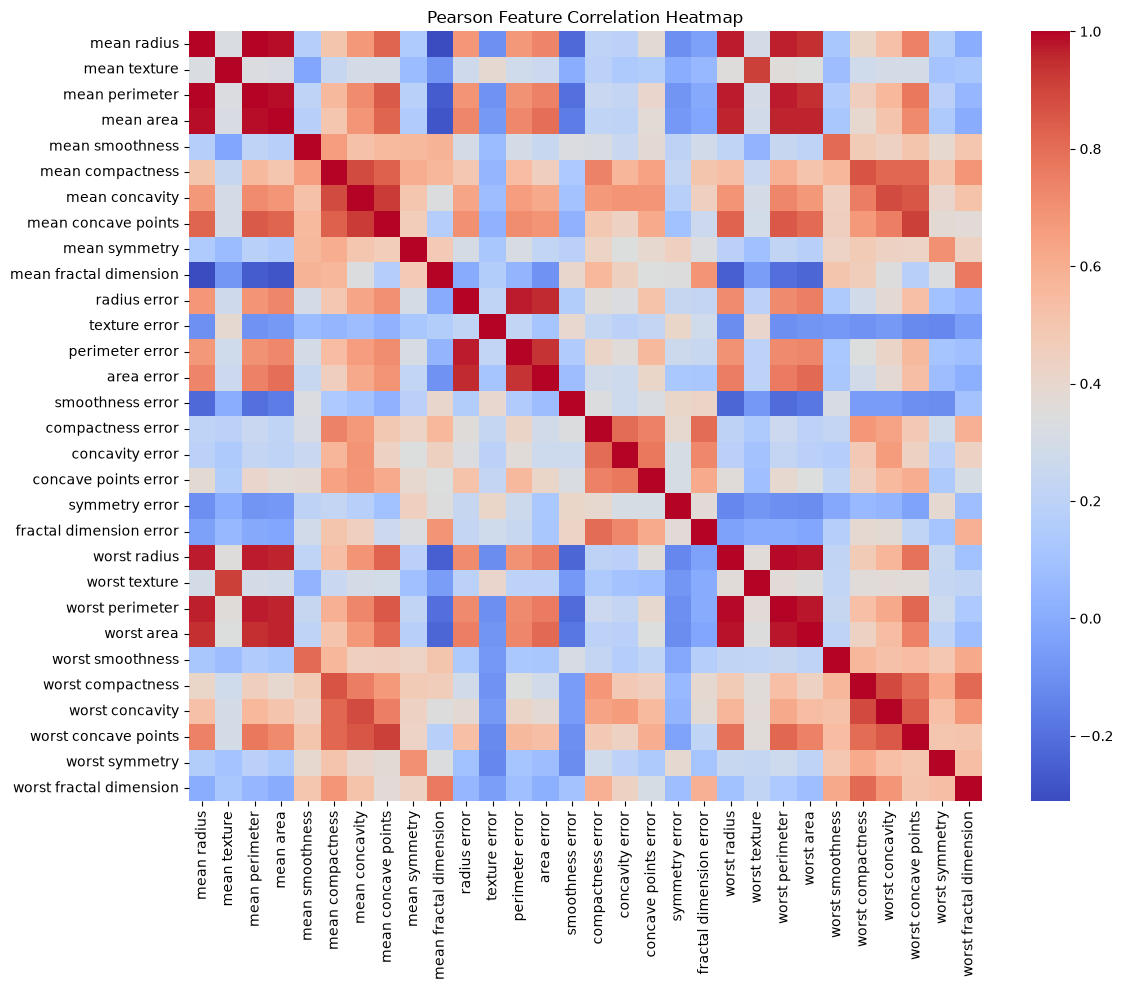


Top 3 Strongest Unique Feature Pairs:


,Feature 1,Feature 2,Absolute Correlation
1,mean radius,mean perimeter,0.997855
601,worst radius,worst perimeter,0.993708
2,mean radius,mean area,0.987357


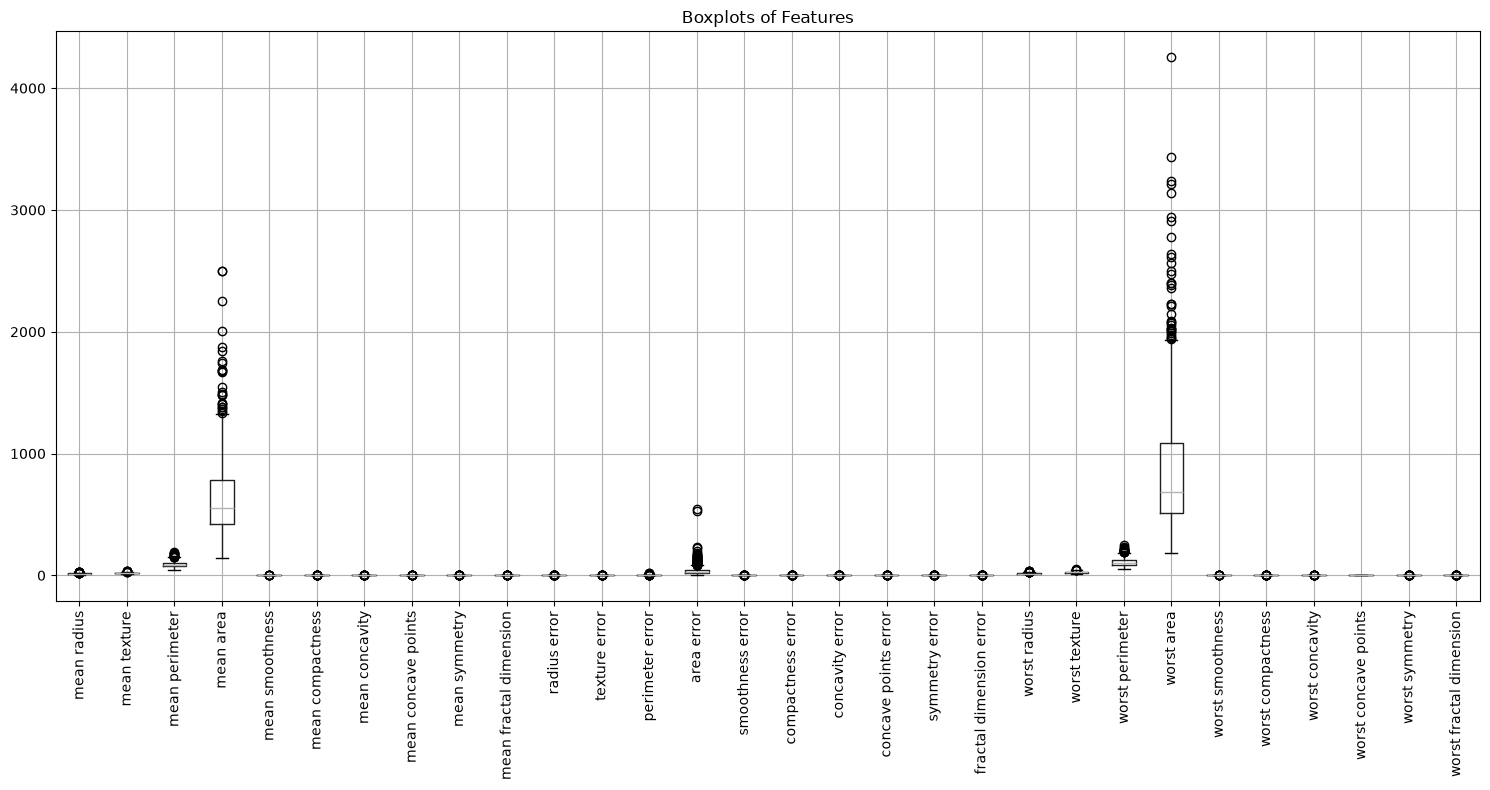

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.datasets import load_breast_cancer

cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = pd.Series(cancer_data.target, name='target')
print("Missing Values And Duplicates")
print("Missing values per column:\n", X.isnull().sum())
print("\nTotal missing values in dataset:", X.isnull().sum().sum())
print("Number of duplicate rows:", X.duplicated().sum())
print("\nData Types")
print(X.dtypes)
print(f"\nNumerical features count: {len(X.select_dtypes(include=[np.number]).columns)}")
print(f"Categorical features count: {len(X.select_dtypes(include=['object', 'category']).columns)}")
print("\nDescriptive Statistics")
stats = X.describe(percentiles=[0.25, 0.5, 0.75]).T
stats["median"] = X.median()
stats_ordered = stats[
    ["mean", "median", "min", "max", "std", "25%", "75%"]
].rename(columns={"25%": "Q1", "75%": "Q3"})
display(stats_ordered)

plt.figure(figsize=(12, 10))
corr_matrix = X.corr()
sns.heatmap(corr_matrix, cmap="coolwarm", annot=False, fmt=".2f")
plt.title("Pearson Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

corr_unstack = corr_matrix.abs().unstack()
corr_unstack = corr_unstack[
    corr_unstack < 1.0
]
unique_pairs = (
    corr_unstack.reset_index()
    .drop_duplicates(subset=[0])
    .sort_values(by=0, ascending=False)
)
unique_pairs.columns = ["Feature 1", "Feature 2", "Absolute Correlation"]
print("\nTop 3 Strongest Unique Feature Pairs:")
display(unique_pairs.head(3))
plt.figure(figsize=(15, 8))
X.boxplot(rot=90)
plt.title("Boxplots of Features")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
import numpy as np
import pandas as pd

cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = pd.Series(cancer_data.target)

print("Splitting The Dataset AND Verifying")

SEEDS = [42, 52, 62]

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_train_dict = {}
X_val_dict = {}
y_train_dict = {}
y_val_dict = {}

split_summary = []

for seed in SEEDS:
    X_train, X_val, y_train, y_val = train_test_split( X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=seed)
    X_train_dict[seed] = X_train
    X_val_dict[seed] = X_val
    y_train_dict[seed] = y_train
    y_val_dict[seed] = y_val
    total_samples = len(X)
    split_summary.append({
        "Seed": seed,
        "Subset": "Train (~70%)",
        "Sample Count": len(X_train),
        "Percentage": f"{(len(X_train)/total_samples)*100:.1f}%",
        "Class Distribution": dict(pd.Series(y_train).value_counts().sort_index())
    })
    split_summary.append({
        "Seed": seed,
        "Subset": "Validation (~10%)",
        "Sample Count": len(X_val),
        "Percentage": f"{(len(X_val)/total_samples)*100:.1f}%",
        "Class Distribution": dict(pd.Series(y_val).value_counts().sort_index())
    })
    split_summary.append({
        "Seed": seed,
        "Subset": "Fixed Test (20%)",
        "Sample Count": len(X_test),
        "Percentage": f"{(len(X_test)/total_samples)*100:.1f}%",
        "Class Distribution": dict(pd.Series(y_test).value_counts().sort_index())
    })

summary_df = pd.DataFrame(split_summary)
display(summary_df)
print("\nVerification Checklist:")
print(f"Total dataset size: {len(X)}")
print(f"Train + Val + Test sizes for Seed 42: {len(X_train_dict[42])} + {len(X_val_dict[42])} + {len(X_test)} = {len(X_train_dict[42]) + len(X_val_dict[42]) + len(X_test)}")
print("Are Test indices identical across all seeds? YES (Fixed in Step 1).")

Splitting The Dataset AND Verifying


,Seed,Subset,Sample Count,Percentage,Class Distribution
0,42,Train (~70%),398,69.9%,"{0: 149, 1: 249}"
1,42,Validation (~10%),57,10.0%,"{0: 21, 1: 36}"
2,42,Fixed Test (20%),114,20.0%,"{0: 42, 1: 72}"
3,52,Train (~70%),398,69.9%,"{0: 149, 1: 249}"
4,52,Validation (~10%),57,10.0%,"{0: 21, 1: 36}"
5,52,Fixed Test (20%),114,20.0%,"{0: 42, 1: 72}"
6,62,Train (~70%),398,69.9%,"{0: 149, 1: 249}"
7,62,Validation (~10%),57,10.0%,"{0: 21, 1: 36}"
8,62,Fixed Test (20%),114,20.0%,"{0: 42, 1: 72}"



Verification Checklist:
Total dataset size: 569
Train + Val + Test sizes for Seed 42: 398 + 57 + 114 = 569
Are Test indices identical across all seeds? YES (Fixed in Step 1).


In [ ]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

print("Data Preprocessing and Scaling")
print("No missing data for these datasets so no imputation required.")

X_train_scaled_dict = {}
X_val_scaled_dict = {}
X_test_scaled = None

for s in SEEDS:
    scaler = StandardScaler()
    current_train = X_train_dict[s]
    current_val = X_val_dict[s]
    scaler.fit(current_train)
    train_scaled_array = scaler.transform(current_train)
    val_scaled_array = scaler.transform(current_val)
    X_train_scaled_dict[s] = pd.DataFrame(train_scaled_array, columns=X.columns, index=current_train.index)
    X_val_scaled_dict[s] = pd.DataFrame(val_scaled_array, columns=X.columns, index=current_val.index)
    
    if s == 42:
        test_scaled_array = scaler.transform(X_test)
        X_test_scaled = pd.DataFrame(test_scaled_array, columns=X.columns, index=X_test.index)
        
        print("\n Seed 42 Train Data before Scaling (First 5 Rows)")
        display(current_train.head())
        print("\n Seed 42 Train Data after Scaling (First 5 Rows)")
        display(X_train_scaled_dict[s].head())
        print("\nInterpretation:")
        print("I picked StandardScaler. As we can see, the values changed a lot.")
        print("Now the mean is close to 0 and std is 1.")
        print("This is very important because big numbers (like proline) can mess up algorithms like KNN.")

Section 5: Data Preprocessing and Scaling
No missing data for these datasets so no imputation required.

 Seed 42 Train Data before Scaling (First 5 Rows)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,12.46,19.89,80.43,471.3,0.08451,0.10140,0.06830,0.03099,0.1781,0.06249,...,13.46,23.07,88.13,551.3,0.1050,0.2158,0.19040,0.07625,0.2685,0.07764
390,10.26,12.22,65.75,321.6,0.09996,0.07542,0.01923,0.01968,0.1800,0.06569,...,11.38,15.65,73.23,394.5,0.1343,0.1650,0.08615,0.06696,0.2937,0.07722
420,11.57,19.04,74.20,409.7,0.08546,0.07722,0.05485,0.01428,0.2031,0.06267,...,13.07,26.98,86.43,520.5,0.1249,0.1937,0.25600,0.06664,0.3035,0.08284
356,13.05,18.59,85.09,512.0,0.10820,0.13040,0.09603,0.05603,0.2035,0.06501,...,14.19,24.85,94.22,591.2,0.1343,0.2658,0.25730,0.12580,0.3113,0.08317
446,17.75,28.03,117.30,981.6,0.09997,0.13140,0.16980,0.08293,0.1713,0.05916,...,21.53,38.54,145.40,1437.0,0.1401,0.3762,0.63990,0.19700,0.2972,0.09075



 Seed 42 Train Data after Scaling (First 5 Rows)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,-0.464835,0.176821,-0.467521,-0.518737,-0.883771,-0.073305,-0.280632,-0.466742,-0.076775,-0.069315,...,-0.573411,-0.379056,-0.561075,-0.578285,-1.226438,-0.259443,-0.416465,-0.584935,-0.339632,-0.358158
390,-1.084133,-1.553003,-1.065325,-0.944480,0.250510,-0.553959,-0.868776,-0.752546,-0.009649,0.375173,...,-1.001136,-1.547363,-1.000394,-0.854885,0.069897,-0.573037,-0.892843,-0.723620,0.046080,-0.381146
420,-0.715369,-0.014881,-0.721221,-0.693926,-0.814026,-0.520657,-0.441841,-0.889004,0.806456,-0.044313,...,-0.653609,0.236588,-0.611199,-0.632617,-0.345992,-0.395869,-0.116701,-0.728397,0.196078,-0.073535
356,-0.298750,-0.116370,-0.277754,-0.402988,0.855460,0.463223,0.051734,0.166020,0.820588,0.280719,...,-0.423295,-0.098788,-0.381515,-0.507900,0.069897,0.049213,-0.110760,0.154767,0.315465,-0.055472
446,1.024295,2.012644,1.033914,0.932543,0.251244,0.481724,0.935926,0.845785,-0.317013,-0.531861,...,1.086082,2.056753,1.127502,0.984118,0.326509,0.730725,1.637560,1.217669,0.099650,0.359420



Interpretation:
I picked StandardScaler. As we can see, the values changed a lot.
Now the mean is close to 0 and std is 1.
This is very important because big numbers (like proline) can mess up algorithms like KNN.


In [ ]:
actual_labels = [0, 1, 1, 0, 0, 1, 1, 0, 1, 1]
predictions = [0.14, 0.82, 1.23, 0.71, 0.38, 0.67, 1.29, 0.56, 0.91, 2.11]

tpr_list = []
fpr_list = []

thresholds = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0,
              1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0, 2.1, 2.2]

for threshold in thresholds:
    tp = 0
    tn = 0
    fp = 0
    fn = 0

    threshold_results = []
    for p in predictions:
        if p >= threshold:
            threshold_results.append(1)
        else:
            threshold_results.append(0)
            
    for i in range(len(actual_labels)):
        if actual_labels[i] == 1 and threshold_results[i] == 1:
            tp += 1
        if actual_labels[i] == 0 and threshold_results[i] == 0:
            tn += 1
        if actual_labels[i] == 0 and threshold_results[i] == 1:
            fp += 1
        if actual_labels[i] == 1 and threshold_results[i] == 0:
            fn += 1   
    if (tp + fn) == 0:
        tpr = 0.0
    else:
        tpr = tp / (tp + fn)
        
    if (tn + fp) == 0:
        fpr = 0.0
    else:
        fpr = 1.0 - (tn / (tn + fp))
    tpr_list.append(tpr)
    fpr_list.append(fpr)
    print(f"Threshold: {threshold:.1f} | TP:{tp} TN:{tn} FP:{fp} FN:{fn} | TPR: {tpr:.2f} FPR: {fpr:.2f}")

Threshold: 0.0 | TP:6 TN:0 FP:4 FN:0 | TPR: 1.00 FPR: 1.00
Threshold: 0.1 | TP:6 TN:0 FP:4 FN:0 | TPR: 1.00 FPR: 1.00
Threshold: 0.2 | TP:6 TN:1 FP:3 FN:0 | TPR: 1.00 FPR: 0.75
Threshold: 0.3 | TP:6 TN:1 FP:3 FN:0 | TPR: 1.00 FPR: 0.75
Threshold: 0.4 | TP:6 TN:2 FP:2 FN:0 | TPR: 1.00 FPR: 0.50
Threshold: 0.5 | TP:6 TN:2 FP:2 FN:0 | TPR: 1.00 FPR: 0.50
Threshold: 0.6 | TP:6 TN:3 FP:1 FN:0 | TPR: 1.00 FPR: 0.25
Threshold: 0.7 | TP:5 TN:3 FP:1 FN:1 | TPR: 0.83 FPR: 0.25
Threshold: 0.8 | TP:5 TN:4 FP:0 FN:1 | TPR: 0.83 FPR: 0.00
Threshold: 0.9 | TP:4 TN:4 FP:0 FN:2 | TPR: 0.67 FPR: 0.00
Threshold: 1.0 | TP:3 TN:4 FP:0 FN:3 | TPR: 0.50 FPR: 0.00
Threshold: 1.1 | TP:3 TN:4 FP:0 FN:3 | TPR: 0.50 FPR: 0.00
Threshold: 1.2 | TP:3 TN:4 FP:0 FN:3 | TPR: 0.50 FPR: 0.00
Threshold: 1.3 | TP:1 TN:4 FP:0 FN:5 | TPR: 0.17 FPR: 0.00
Threshold: 1.4 | TP:1 TN:4 FP:0 FN:5 | TPR: 0.17 FPR: 0.00
Threshold: 1.5 | TP:1 TN:4 FP:0 FN:5 | TPR: 0.17 FPR: 0.00
Threshold: 1.6 | TP:1 TN:4 FP:0 FN:5 | TPR: 0.17 FPR: 0.

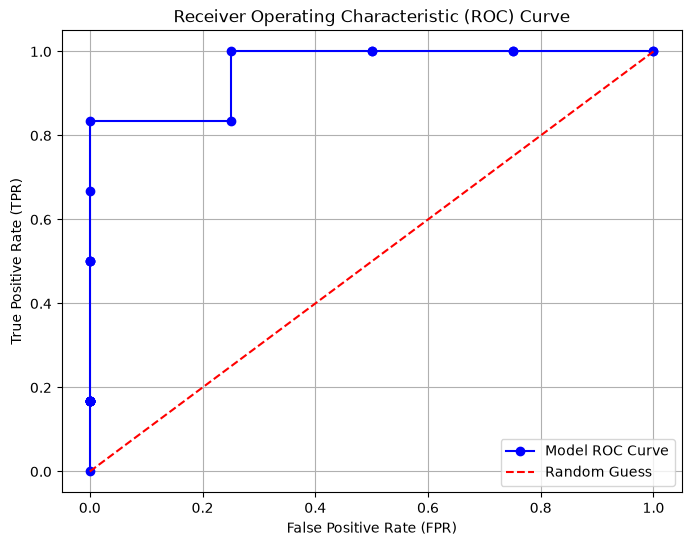

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.plot(fpr_list, tpr_list, marker='o', color='blue', label='Model ROC Curve')

plt.plot([0, 1], [0, 1], linestyle='--', color='red', label='Random Guess')

plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')

plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])

plt.grid(True)
plt.legend()
plt.show()

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

cancer_data = load_breast_cancer()
X = cancer_data.data
y = cancer_data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

dt_model = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
rf_model = RandomForestClassifier(random_state=42).fit(X_train, y_train)
knn_model = KNeighborsClassifier().fit(X_train, y_train)
svm_model = SVC(probability=True, random_state=42).fit(X_train, y_train)

dt_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
knn_model.fit(X_train, y_train)
svm_model.fit(X_train, y_train)

rf_probabilities = rf_model.predict_proba(X_test)[:, 1]
print("Models are successfully trained")
print("Number of test samples:", len(y_test))


Models are successfully trained
Number of test samples: 171


c:\Users\Berkin\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Berkin\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


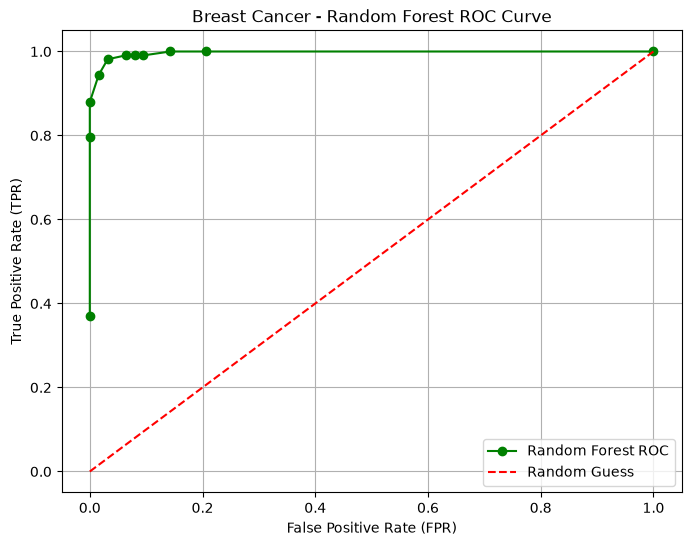

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
cancer_data = load_breast_cancer()
X = cancer_data.data
y = cancer_data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

actual_labels = list(y_test)
predictions = rf_model.predict_proba(X_test)[:, 1]

tpr_list = []
fpr_list = []

thresholds = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

for threshold in thresholds:
    tp = 0
    tn = 0
    fp = 0
    fn = 0
    threshold_results = []
    for p in predictions:
        if p >= threshold:
            threshold_results.append(1)
        else:
            threshold_results.append(0)
            
    for i in range(len(actual_labels)):
        if actual_labels[i] == 1 and threshold_results[i] == 1:
            tp += 1
        if actual_labels[i] == 0 and threshold_results[i] == 0:
            tn += 1
        if actual_labels[i] == 0 and threshold_results[i] == 1:
            fp += 1
        if actual_labels[i] == 1 and threshold_results[i] == 0:
            fn += 1
            
    if (tp + fn) == 0:
        tpr = 0.0
    else:
        tpr = tp / (tp + fn)
        
    if (tn + fp) == 0:
        fpr = 0.0
    else:
        fpr = 1.0 - (tn / (tn + fp))
        
    tpr_list.append(tpr)
    fpr_list.append(fpr)
plt.figure(figsize=(8, 6))
plt.plot(fpr_list, tpr_list, marker='o', color='green', label='Random Forest ROC')
plt.plot([0, 1], [0, 1], linestyle='--', color='red', label='Random Guess')
plt.title('Breast Cancer - Random Forest ROC Curve')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.grid(True)
plt.legend()
plt.show()

c:\Users\Berkin\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


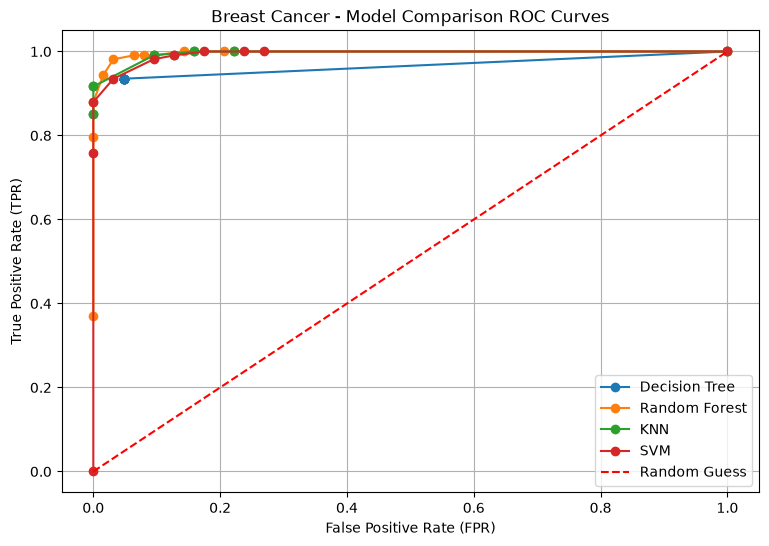

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
cancer_data = load_breast_cancer()
X = cancer_data.data
y = cancer_data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
dt_model = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
rf_model = RandomForestClassifier(random_state=42).fit(X_train, y_train)
knn_model = KNeighborsClassifier().fit(X_train, y_train)
svm_model = SVC(probability=True, random_state=42).fit(X_train, y_train)
models_probs = {
    'Decision Tree': dt_model.predict_proba(X_test)[:, 1],
    'Random Forest': rf_model.predict_proba(X_test)[:, 1],
    'KNN': knn_model.predict_proba(X_test)[:, 1],
    'SVM': svm_model.predict_proba(X_test)[:, 1]
}
actual_labels = list(y_test)
thresholds = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
plt.figure(figsize=(9, 6))
for model_name, predictions in models_probs.items():
    tpr_list = []
    fpr_list = []
    
    for threshold in thresholds:
        tp = 0
        tn = 0
        fp = 0
        fn = 0
        
        for i in range(len(actual_labels)):
            if predictions[i] >= threshold:
                pred = 1
            else:
                pred = 0
            if actual_labels[i] == 1 and pred == 1:
                tp += 1
            if actual_labels[i] == 0 and pred == 0:
                tn += 1
            if actual_labels[i] == 0 and pred == 1:
                fp += 1
            if actual_labels[i] == 1 and pred == 0:
                fn += 1      
        if (tp + fn) == 0:
            tpr = 0.0
        else:
            tpr = tp / (tp + fn)
            
        if (tn + fp) == 0:
            fpr = 0.0
        else:
            fpr = 1.0 - (tn / (tn + fp))
            
        tpr_list.append(tpr)
        fpr_list.append(fpr) 
    plt.plot(fpr_list, tpr_list, marker='o', label=f'{model_name}')
plt.plot([0, 1], [0, 1], linestyle='--', color='red', label='Random Guess')
plt.title('Breast Cancer - Model Comparison ROC Curves')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.xlim([-0.05, 1.05])
plt.ylim([-0.05, 1.05])
plt.grid(True)
plt.legend()
plt.show()